# CMPS261 Project - Amazon Shopping Queries (ESCI)
Mazen Hachem, Ram Haidar, Karim Nabaa

The goal is to predict if a product is Exact (E), Substitute (S), Complement (C) or Irrelevant (I) for a search query.

- Part 1: data + preprocessing (Mazen)
- Part 2: baselines, TF-IDF + logistic regression and boosted trees (Ram)
- Part 3: fine-tuning a small BERT model (Karim)
- Part 4: final test results and comparing the models



Metrics: we mainly look at macro F1 because the classes are very unbalanced. We also report accuracy,
F1 for each class and nDCG (how good the ranking of products is for each query, using the ESCI gains
E=1, S=0.1, C=0.01, I=0). All the choices are made on validation, the test set is only used in Part 4.


## 0. Setup
install rapidfuzz and download the dataset from the amazon github (around 1.2GB)

In [1]:
!pip -q install rapidfuzz

In [2]:
import urllib.request
from pathlib import Path

RAW = Path("data/raw")
RAW.mkdir(parents=True, exist_ok=True)
URL = "https://github.com/amazon-science/esci-data/raw/main/shopping_queries_dataset/"
for f in ["shopping_queries_dataset_examples.parquet", "shopping_queries_dataset_products.parquet"]:
    if not (RAW / f).exists():
        print("downloading", f)
        urllib.request.urlretrieve(URL + f, RAW / f)
    print(f, f"{(RAW / f).stat().st_size / 1e6:.0f} MB")

downloading shopping_queries_dataset_examples.parquet
shopping_queries_dataset_examples.parquet 51 MB
downloading shopping_queries_dataset_products.parquet
shopping_queries_dataset_products.parquet 1109 MB


In [3]:
import copy
import gc
import html
import re
import time

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import scipy.sparse as sp
import torch
from rapidfuzz import fuzz
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, f1_score, ndcg_score
from sklearn.preprocessing import StandardScaler
from torch.utils.data import DataLoader
from transformers import AutoModelForSequenceClassification, AutoTokenizer, get_linear_schedule_with_warmup

PROCESSED, RESULTS, MODELS = Path("data/processed"), Path("results"), Path("models")
for d in (PROCESSED, RESULTS, MODELS):
    d.mkdir(parents=True, exist_ok=True)
for old in RESULTS.glob("*_results.csv"):
    old.unlink()

SEED = 42
LABELS = ["E", "S", "C", "I"]  # Exact, Substitute, Complement, Irrelevant
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
GAINS = {"E": 1.0, "S": 0.1, "C": 0.01, "I": 0.0}
GAIN_VEC = np.array(list(GAINS.values()))

### Helper functions
we use the same functions to evaluate all the models so the results are comparable

In [4]:
def load_split(name):
    return pd.read_parquet(PROCESSED / f"{name}.parquet")


def ndcg_per_query(query_ids, true_labels, scores):
    df = pd.DataFrame({"q": np.asarray(query_ids), "g": [GAINS[l] for l in true_labels], "s": np.asarray(scores)})
    out = []
    for _, grp in df.groupby("q", sort=False):
        g = grp["g"].to_numpy()
        if g.max() <= 0:
            continue
        if len(g) == 1:
            out.append(1.0)
        else:
            out.append(ndcg_score(g[None, :], grp["s"].to_numpy()[None, :], ignore_ties=False))
    return float(np.mean(out))


def predict_labels(proba, offsets=None):
    proba = np.asarray(proba)
    if offsets is None:
        return proba.argmax(1)
    return (np.log(proba + 1e-9) + offsets).argmax(1)


def macro_f1(y_true, y_pred):
    return f1_score(y_true, y_pred, average="macro", labels=range(4), zero_division=0)


def evaluate(df, proba, name, offsets=None):
    y_true = df["esci_label"].map(LABEL2ID).to_numpy()
    y_pred = predict_labels(proba, offsets)
    res = {
        "model": name,
        "macro-F1": macro_f1(y_true, y_pred),
        "accuracy (micro-F1)": accuracy_score(y_true, y_pred),
        "nDCG": ndcg_per_query(df["query_id"], df["esci_label"], np.asarray(proba) @ GAIN_VEC),
    }
    for l, f in zip(LABELS, f1_score(y_true, y_pred, average=None, labels=range(4), zero_division=0)):
        res[f"F1_{l}"] = f
    return res


def report(df, proba, offsets=None):
    y_true = df["esci_label"].map(LABEL2ID).to_numpy()
    y_pred = predict_labels(proba, offsets)
    print(classification_report(y_true, y_pred, labels=range(4), target_names=LABELS, digits=3, zero_division=0))
    return pd.DataFrame(confusion_matrix(y_true, y_pred, labels=range(4)), index=[f"true_{l}" for l in LABELS],
                        columns=[f"pred_{l}" for l in LABELS])


def tune_offsets(df, proba, grid=np.linspace(-3, 3, 25), rounds=2):
    y = df["esci_label"].map(LABEL2ID).to_numpy()
    logp = np.log(np.asarray(proba) + 1e-9)
    off = np.zeros(4)
    best = macro_f1(y, logp.argmax(1))
    for _ in range(rounds):
        for c in range(1, 4):
            for v in grid:
                o = off.copy()
                o[c] = v
                s = macro_f1(y, (logp + o).argmax(1))
                if s > best:
                    best, off = s, o
    return off


def save_result(res, split):
    path = RESULTS / f"{split}_results.csv"
    df = pd.read_csv(path) if path.exists() else pd.DataFrame(columns=["model"])
    df = pd.concat([df[df.model != res["model"]], pd.DataFrame([res])], ignore_index=True)
    df.to_csv(path, index=False)

---
# Part 1 - Data and preprocessing (Mazen)

Some choices we made:
- we only kept the English (us) queries since the BERT model we use is English
- we used the large version of the dataset, which is the one for the 4 class task
- the test set is from the official test split, and validation is taken from the train split
- we split train and validation by query so the same query is never in both, otherwise the model could
  just memorize queries and the validation score would be too high
- the full data is too big for Colab memory so we sample queries (we keep all the products of a query
  because nDCG is computed per query)

In [5]:
N_TRAIN_Q, N_VAL_Q, N_TEST_Q = 20_000, 3_000, 4_000  # number of queries (not rows)

examples = pd.read_parquet(RAW / "shopping_queries_dataset_examples.parquet")
print(examples.shape)
examples.head()

(2621288, 9)


,example_id,query,query_id,product_id,product_locale,esci_label,small_version,large_version,split
0,0,revent 80 cfm,0,B000MOO21W,us,I,0,1,train
1,1,revent 80 cfm,0,B07X3Y6B1V,us,E,0,1,train
2,2,revent 80 cfm,0,B07WDM7MQQ,us,E,0,1,train
3,3,revent 80 cfm,0,B07RH6Z8KW,us,E,0,1,train
4,4,revent 80 cfm,0,B07QJ7WYFQ,us,E,0,1,train


In [6]:
ex = examples[(examples.product_locale == "us") & (examples.large_version == 1)].copy()
del examples
print(f"US / large version: {len(ex):,} pairs, {ex.query_id.nunique():,} queries")
print(ex.split.value_counts())

US / large version: 1,818,825 pairs, 97,345 queries
split
train    1393063
test      425762
Name: count, dtype: int64


### 1.1 EDA (on the official train split only, we don't look at the test labels)

{'E': 0.696, 'S': 0.197, 'C': 0.021, 'I': 0.086}
pairs per query: {'count': 74888.0, 'mean': 18.6, 'std': 7.9, 'min': 3.0, '25%': 16.0, '50%': 16.0, '75%': 16.0, 'max': 198.0}
query length (words): {'count': 74888.0, 'mean': 3.5, 'std': 1.6, 'min': 1.0, '25%': 2.0, '50%': 3.0, '75%': 4.0, 'max': 29.0}


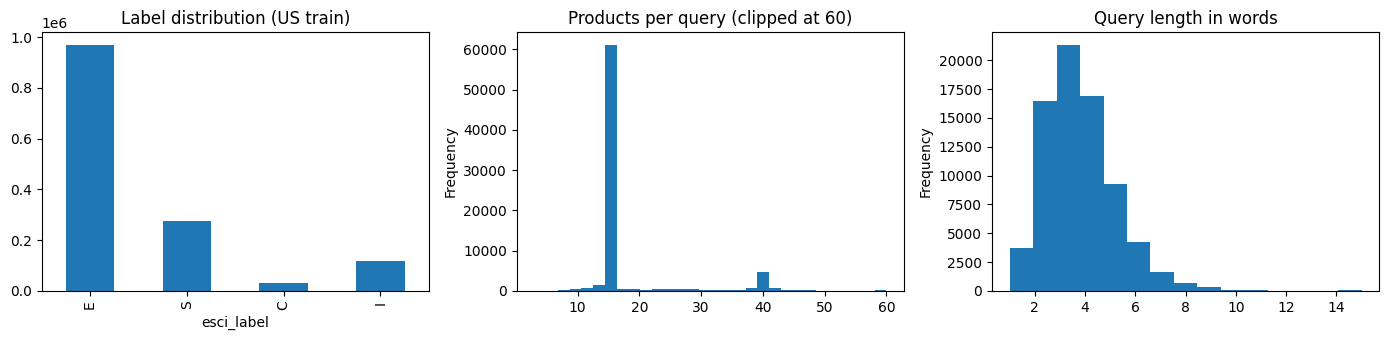

In [7]:
eda = ex[ex.split == "train"]
print(eda.esci_label.value_counts(normalize=True)[LABELS].round(3).to_dict())

pairs_per_q = eda.groupby("query_id").size()
q_len = eda.drop_duplicates("query_id")["query"].str.split().str.len()
print("pairs per query:", pairs_per_q.describe().round(1).to_dict())
print("query length (words):", q_len.describe().round(1).to_dict())

fig, ax = plt.subplots(1, 3, figsize=(14, 3.5))
eda.esci_label.value_counts()[LABELS].plot.bar(ax=ax[0], title="Label distribution (US train)")
pairs_per_q.clip(upper=60).plot.hist(bins=30, ax=ax[1], title="Products per query (clipped at 60)")
q_len.clip(upper=15).plot.hist(bins=15, ax=ax[2], title="Query length in words")
plt.tight_layout()
plt.savefig(RESULTS / "eda.png", dpi=150)
plt.show()
del eda

The labels are really unbalanced, around 70% are Exact and only 2% Complement. So if a model always says Exact it
already gets 70% accuracy, that's why we use macro F1 as our main metric.

### 1.2 Sampling queries and making the splits
a few query ids are in both official splits, we remove them from the train side so they can't leak into test

In [8]:
rng = np.random.default_rng(SEED)
train_q_all = ex.loc[ex.split == "train", "query_id"].unique()
test_q_all = ex.loc[ex.split == "test", "query_id"].unique()
shared = np.intersect1d(train_q_all, test_q_all)
print("query ids in both official splits:", len(shared))
train_q_all = np.setdiff1d(train_q_all, shared)

picked = rng.choice(train_q_all, N_TRAIN_Q + N_VAL_Q, replace=False)
train_q, val_q = picked[:N_TRAIN_Q], picked[N_TRAIN_Q:]
test_q = rng.choice(test_q_all, N_TEST_Q, replace=False)

parts = {
    "train": ex[(ex.split == "train") & ex.query_id.isin(train_q)],
    "val": ex[(ex.split == "train") & ex.query_id.isin(val_q)],
    "test": ex[(ex.split == "test") & ex.query_id.isin(test_q)],
}
for k, v in parts.items():
    print(f"{k:5s}: {len(v):7,} pairs, {v.query_id.nunique():6,} queries")

norm = lambda d: set(d["query"].str.lower().str.split().str.join(" "))
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    assert set(parts[a].query_id).isdisjoint(parts[b].query_id), f"query leakage {a}/{b}"
    print(f"{a}/{b}: same query text in both = {len(norm(parts[a]) & norm(parts[b]))}")

query ids in both official splits: 1
train: 373,188 pairs, 20,000 queries
val  :  55,065 pairs,  3,000 queries
test :  76,226 pairs,  4,000 queries
train/val: same query text in both = 0
train/test: same query text in both = 0
val/test: same query text in both = 0


### 1.3 Adding the product info and cleaning
the products file is big (1GB) so we only load the US products and the columns we need

In [9]:
needed = set(pd.concat(parts.values()).product_id)
products = pq.read_table(
    RAW / "shopping_queries_dataset_products.parquet",
    columns=["product_id", "product_locale", "product_title", "product_brand", "product_color",
             "product_bullet_point", "product_description"],
    filters=[("product_locale", "=", "us")],
).to_pandas()
products = products[products.product_id.isin(needed)].drop(columns="product_locale")
print(products.shape)
print("missing values (%):")
print((products.isna().mean() * 100).round(1))

(418740, 6)
missing values (%):
product_id               0.0
product_title            0.0
product_brand            5.2
product_color           31.6
product_bullet_point    13.1
product_description     48.6
dtype: float64


In [10]:
TAG = re.compile(r"<[^>]+>")
SPACE = re.compile(r"\s+")


def clean(text):
    if not isinstance(text, str):
        return ""
    text = html.unescape(TAG.sub(" ", text))
    return SPACE.sub(" ", text).strip()


for col in ["product_title", "product_brand", "product_color", "product_bullet_point", "product_description"]:
    products[col] = products[col].map(clean)

for name, df in parts.items():
    df = df[["example_id", "query_id", "query", "product_id", "esci_label"]].merge(
        products, on="product_id", how="left", validate="many_to_one")
    df["query"] = df["query"].map(clean)
    df = df.fillna("")
    df.to_parquet(PROCESSED / f"{name}.parquet", index=False)
    print(name, df.shape, "label share:", df.esci_label.value_counts(normalize=True)[LABELS].round(3).to_dict())

del ex, parts, products
gc.collect()

train (373188, 10) label share: {'E': 0.699, 'S': 0.195, 'C': 0.02, 'I': 0.085}
val (55065, 10) label share: {'E': 0.7, 'S': 0.195, 'C': 0.021, 'I': 0.085}
test (76226, 10) label share: {'E': 0.644, 'S': 0.226, 'C': 0.026, 'I': 0.104}


97

### 1.4 Hard examples
Here we look at products labeled Irrelevant even though the title has all the words of the query.
We think these will be hard for TF-IDF since it only looks at matching words.

In [11]:
train, val, test = load_split("train"), load_split("val"), load_split("test")


def overlap(q, t):
    q, t = set(q.lower().split()), set(t.lower().split())
    return len(q & t) / max(len(q), 1)


train_overlap = np.array([overlap(q, t) for q, t in zip(train["query"], train.product_title)])
print("mean fraction of query words in title, per label:")
print(pd.Series(train_overlap).groupby(train.esci_label.values).mean()[LABELS].round(3))
train.loc[(train.esci_label == "I") & (train_overlap >= 0.99), ["query", "product_title"]].head(10)

mean fraction of query words in title, per label:
E    0.542
S    0.337
C    0.433
I    0.220
dtype: float64


,query,product_title
6662,100% leather couch,HOMFINER Faux Leather and 100% Cotton Decorati...
6663,100% leather couch,DEZENE Faux Leather with 100% Cotton Decorativ...
6664,100% leather couch,Texture + Ink Boho Pillow Covers Throw Pillow ...
8770,12v pa system,Universal Power Group 12V 5AH SLA Battery Repl...
8771,12v pa system,Power Home HiFi Stereo Amplifier - 90 Watt Por...
10729,2 gallon water bottle,"5 Gallon Water Dispenser,Electric Drinking Wat..."
11218,2 tier bathroom shelf,"2 Tier Bathroom Organizer Countertop Holder, B..."
11801,20x25x4 filter honeywell,Honeywell Home Air Filter Ultra Efficiency CF2...
12201,23mm socket,Urrea 7023M 3/8-Inch Drive Deep 6-Point 23mm I...
19195,6s iphone case,"KUMEEK iPhone 6s Plus Case/iPhone 6 Plus Case,..."


---
# Part 2 - Baselines (Ram)
Ram will add his part here

---
# Part 3 - BERT model (Karim)
Karim will add his part here (and part 4)